# Call Center Conversation Analysis Using Machine Learning

#### student name(s): Zolzaya Arild

### Abstract

This project investigates the use of machine learning to estimate completed call center conversation duration from transcript derived characteristics. A subset of 3,239 call transcripts from the CallCenterEN dataset was analyzed using Python, pandas, seaborn, and scikit-learn. Exploratory Data Analysis (EDA) was performed to examine call duration, transcript word count, transcription confidence, and relationships among numerical variables.
After data cleaning, 3,167 records were retained. Three regression algorithms Linear Regression, Random Forest Regression, and Gradient Boosting Regression were trained using transcript word count, transcription confidence, and average word length. A group aware train/test split was applied to prevent identical transcripts from appearing in both datasets.
Linear Regression achieved the best performance on the heldout test set, with a Mean Absolute Error (MAE) of 79.30 seconds, a Root Mean Squared Error (RMSE) of 118.97 seconds, and an R² score of 0.9296. The findings demonstrate that transcript derived numerical features can provide useful estimates of completed call duration. However, because these features require completed transcripts, the approach is not intended for predicting call duration before a conversation begins.

## Table of Content

[Problem](#problem)   
[Data Understanding](#data_understanding)   
[Data Preparation](#data_preparation)   
[Modeling](#modeling)   
[Evaluation](#evaluation)   
[References](#references)   


## Problem <a class="anchor" id="problem"></a>

### Problem Statement

Call centers generate large volumes of customer conversations, but analyzing these conversations manually is time-consuming. Understanding the relationship between transcript characteristics and call duration can help organizations evaluate communication patterns and explore opportunities for operational analysis.

This project investigates whether the duration of completed call center conversations can be estimated using information extracted from their transcripts. The study uses the CallCenterEN dataset and applies exploratory data analysis (EDA), data preprocessing, and supervised machine learning techniques using Python and scikit-learn.

### Research Questions

1. What are the distributions of call duration, transcript length, and transcription confidence?
2. How strongly are transcript characteristics associated with call duration?
3. Can machine learning regression models estimate completed-call duration using transcript-derived features?
4. Which regression model performs best according to MAE, RMSE, and R²?

### Project Objective

The objective is to build, compare, and evaluate regression models for estimating completed-call duration while examining data quality, model limitations, and potential information leakage. Because transcript-derived features are available only after a call has been transcribed, the experiment does not claim to predict call duration before a call begins.

## Data Understanding<a class="anchor" id="data_understanding"></a>

### Dataset Description

This study uses the CallCenterEN dataset, published by AIxBlock on Hugging Face. The dataset contains real-world call center conversation transcripts and associated speech recognition metadata.

**Dataset source:** https://huggingface.co/datasets/AIxBlock/92k-real-world-call-center-scripts-english

For this experiment, a subset containing home service inbound and telecom outbound conversations was downloaded. The extracted subset contains 3,239 JSON transcript files.

Each JSON file includes five main fields:

- **text:** The transcribed call conversation.
- **confidence:** The overall automatic speech recognition (ASR) confidence score.
- **audio_duration:** The duration of the recorded call in seconds.
- **words:** Word-level transcription information, including timestamps and confidence scores.
- **redacted_pii_policies:** A list of personal information redaction policies.

The JSON files were combined into a pandas DataFrame with 3,239 observations and six derived columns: filename, text, confidence, audio_duration, word_count, and pii_types_count.

Initial inspection found no missing values in these six columns. However, further quality checks identified one empty transcript, one zero-confidence record, 123 repeated transcript texts, and 82 calls longer than 30 minutes. These issues will be investigated during data preparation.

The primary target variable is audio_duration. Transcript-derived characteristics will be examined as candidate features for estimating the duration of completed calls.

In [1]:
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.


In [2]:

# Import required libraries
import json
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set the dataset directory
# Load dataset from the project's local data directory
data_folder = Path("data")

# Find all transcript JSON files
json_files = sorted(data_folder.rglob("*.json"))

print("Total JSON files found:", len(json_files))

# Load and combine transcript data
records = []

for file in json_files:
    try:
        with open(file, "r", encoding="utf-8") as f:
            data = json.load(f)

        records.append({
            "filename": file.name,
            "text": data.get("text", ""),
            "confidence": data.get("confidence"),
            "audio_duration": data.get("audio_duration"),
            "word_count": len(data.get("words") or []),
            "pii_types_count": len(
                data.get("redacted_pii_policies") or []
            )
        })

    except (OSError, ValueError, TypeError) as e:
        print(f"Skipped {file.name}: {e}")

# Create the analysis DataFrame
df = pd.DataFrame(records)

# Display the dataset dimensions and first records
print("\nDataset shape:", df.shape)
display(df.head())

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())


Total JSON files found: 3239

Dataset shape: (3239, 6)


,filename,text,confidence,audio_duration,word_count,pii_types_count
0,0043294779c54b03867f0a054b9a0583_transcript.json,It's a great day at [ORGANIZATION] [ORGANIZATI...,0.908789,114,237,44
1,00623ccf8ddd4bec947c601e2e78be40_transcript.json,"Ok. [OCCUPATION], can I help you? Yes, my name...",0.881884,221,363,44
2,00877c48975d44d2a9b8ff0a0aeeffb3_transcript.json,Thank you for calling [ORGANIZATION] [ORGANIZA...,0.903155,147,327,44
3,00ad1d149ddc4bfb8bcba1d74eb563d0_transcript.json,[ORGANIZATION] [ORGANIZATION]. By [PERSON_NAME...,0.849435,329,450,44
4,00c68e223ea54460a78490add7b54fb7_transcript.json,Thank you for calling [ORGANIZATION] [ORGANIZA...,0.924117,719,1586,44



Missing values:
filename           0
text               0
confidence         0
audio_duration     0
word_count         0
pii_types_count    0
dtype: int64


In [3]:
# Display descriptive statistics for numerical variables
# This helps us understand the dataset before preprocessing

columns = ["audio_duration", "word_count", "confidence"]

print("Descriptive Statistics")
display(df[columns].describe().round(2))

# Display the correlation matrix
print("\nCorrelation Matrix")
display(df[columns].corr().round(3))

Descriptive Statistics


,audio_duration,word_count,confidence
count,3239.00,3239.00,3239.00
mean,484.10,948.35,0.88
std,493.79,1044.78,0.03
min,28.00,0.00,0.00
25%,199.50,352.00,0.87
50%,314.00,573.00,0.88
75%,545.00,1042.00,0.90
max,5915.00,12565.00,0.96



Correlation Matrix


,audio_duration,word_count,confidence
audio_duration,1.000,0.954,0.010
word_count,0.954,1.000,0.044
confidence,0.010,0.044,1.000


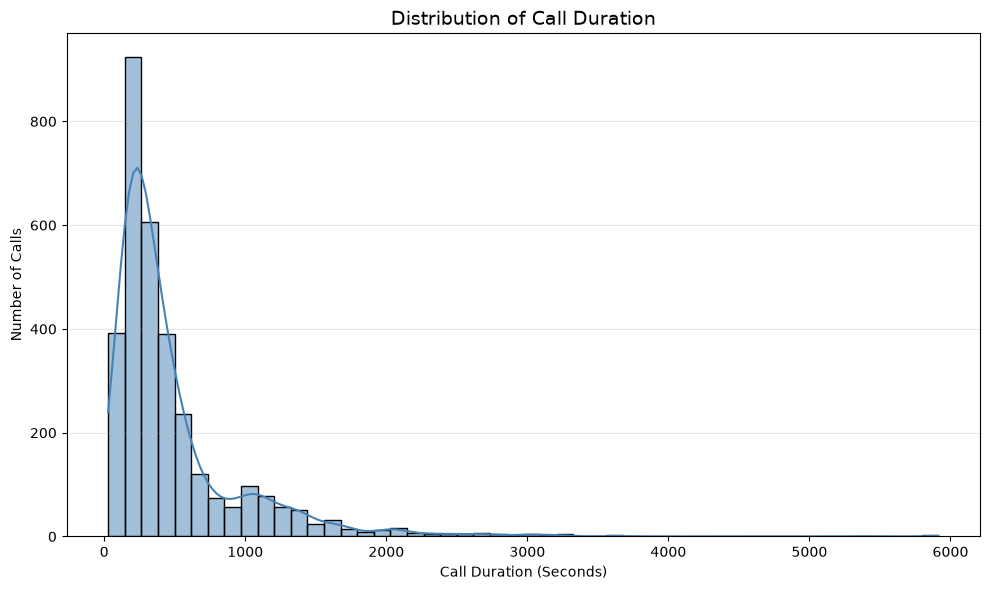

In [4]:
# EDA Chart 1: Distribution of Call Duration
# A histogram shows how frequently different call durations occur.

plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="audio_duration",
    bins=50,
    kde=True,
    color="steelblue"
)

plt.title("Distribution of Call Duration", fontsize=14)
plt.xlabel("Call Duration (Seconds)")
plt.ylabel("Number of Calls")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

**Figure 1. Distribution of Call Duration**

The call duration data shows substantial variation across the 3,239 conversations. The mean duration is 484.10 seconds, while the median is 314 seconds, indicating that longer calls increase the overall average. The maximum duration reaches 5,915 seconds, suggesting the presence of unusually long conversations.

These descriptive statistics are consistent with a positively skewed distribution. The long-duration observations will be examined during data preparation rather than automatically removed, as they may represent legitimate customer interactions.

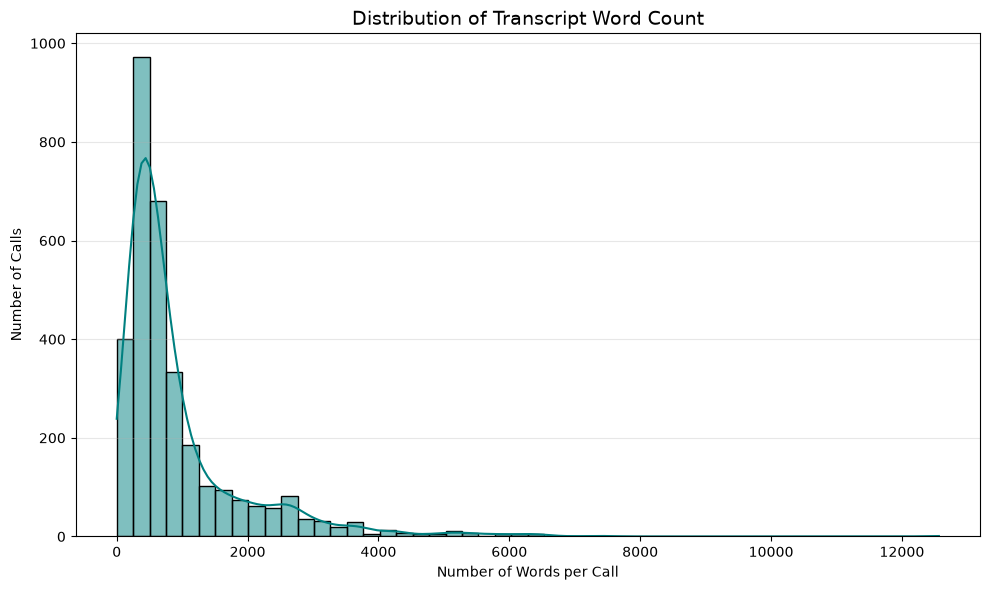

In [5]:

# EDA Chart 2: Distribution of Transcript Word Count
# This histogram shows the distribution of transcribed words per call.

plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="word_count",
    bins=50,
    kde=True,
    color="teal"
)

plt.title("Distribution of Transcript Word Count", fontsize=14)
plt.xlabel("Number of Words per Call")
plt.ylabel("Number of Calls")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


**Figure 2. Distribution of Transcript Word Count**

The histogram shows a positively skewed distribution of transcript word counts across the 3,239 call center conversations. Most transcripts contain relatively few words, while a smaller number of conversations have substantially higher word counts.

The average transcript contains 948.35 words, compared with a median of 573 words. The maximum recorded word count is 12,565, indicating the presence of exceptionally long transcripts.

These findings suggest considerable variation in conversation length. This variation may influence the performance of machine learning models used to estimate completed-call duration.

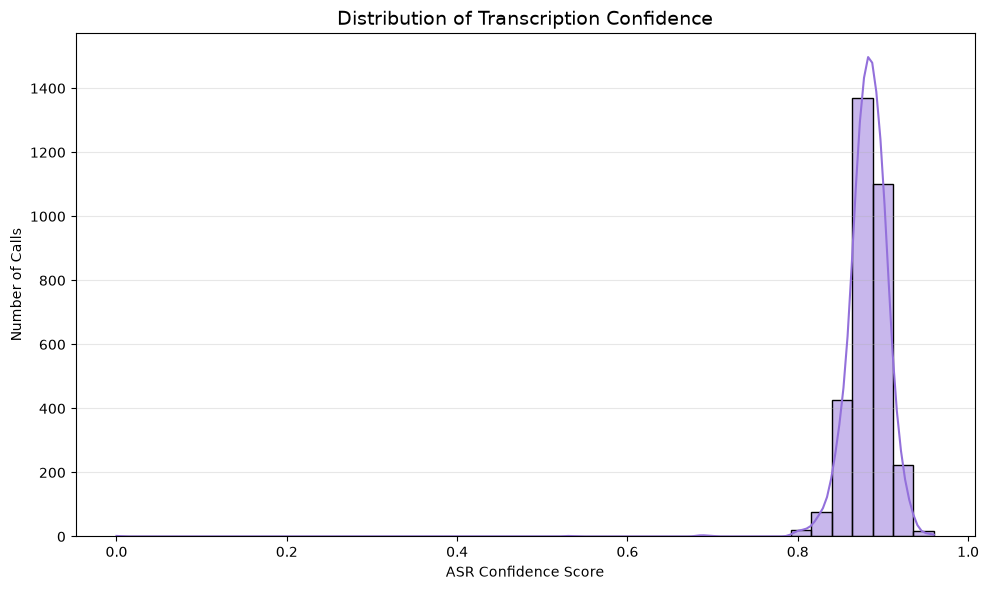

In [6]:

# EDA Chart 3: Distribution of Transcription Confidence
# This histogram shows the distribution of ASR confidence scores.

plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="confidence",
    bins=40,
    kde=True,
    color="mediumpurple"
)

plt.title("Distribution of Transcription Confidence", fontsize=14)
plt.xlabel("ASR Confidence Score")
plt.ylabel("Number of Calls")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


**Figure 3. Distribution of Transcription Confidence**

The dataset contains 3,239 call center transcripts with an average automatic speech recognition (ASR) confidence score of approximately 0.882. The median confidence score is approximately 0.884, indicating that the central values are closely aligned.

The confidence scores range from 0 to approximately 0.960. The zero-confidence observation represents a potential data quality issue that requires further investigation during data preparation.

Overall, the descriptive statistics suggest that transcription confidence is relatively consistent across most conversations. However, confidence scores do not necessarily measure the actual accuracy of the transcripts, and no manually verified transcription accuracy data is available in this analysis.

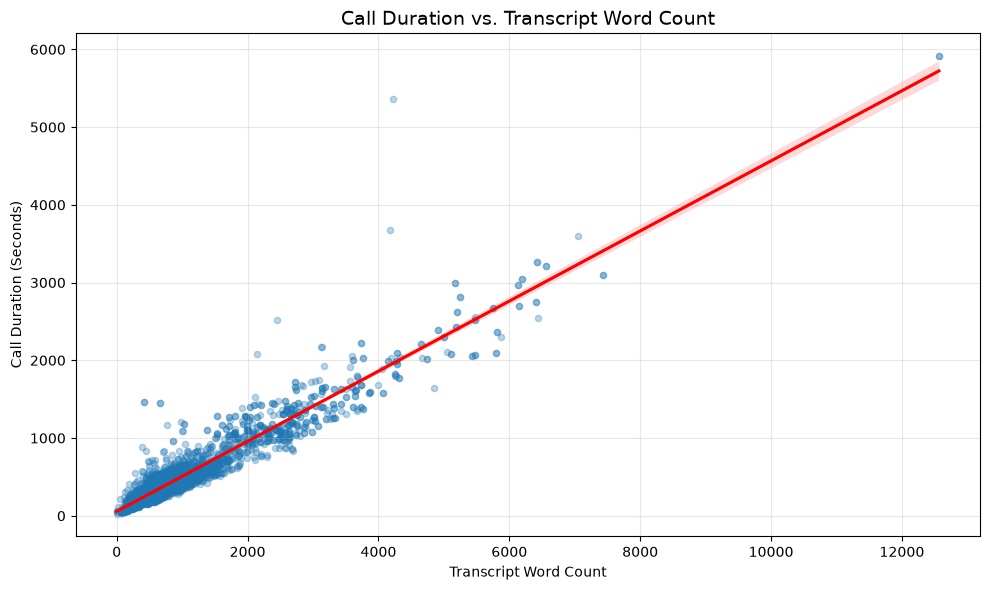

Pearson Correlation: 0.954


In [7]:

# EDA Chart 4: Relationship Between Word Count and Call Duration
# This scatter plot visualizes the association between
# transcript length and completed-call duration.

plt.figure(figsize=(10, 6))

sns.regplot(
    data=df,
    x="word_count",
    y="audio_duration",
    scatter_kws={"alpha": 0.3, "s": 20},
    line_kws={"color": "red"}
)

plt.title("Call Duration vs. Transcript Word Count", fontsize=14)
plt.xlabel("Transcript Word Count")
plt.ylabel("Call Duration (Seconds)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Calculate Pearson correlation coefficient
correlation = df["word_count"].corr(df["audio_duration"])

print(f"Pearson Correlation: {correlation:.3f}")


**Figure 4. Relationship Between Transcript Word Count and Call Duration**

The scatter plot demonstrates a strong positive linear relationship between transcript word count and call duration. The Pearson correlation coefficient is 0.954, indicating that conversations containing more transcribed words generally have longer durations.

Most observations are concentrated in the lower ranges of word count and call duration. However, several unusually long conversations and observations deviating from the overall trend are visible.

This relationship suggests that transcript word count may be a useful predictor of completed-call duration. Nevertheless, word count is calculated from the completed transcript and cannot be used to predict call duration before the conversation takes place. Furthermore, correlation does not establish causation.

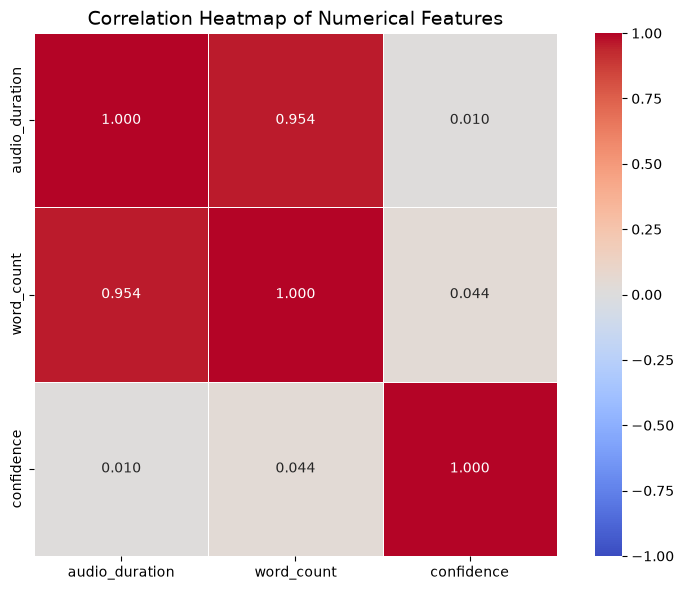

In [8]:

# EDA Chart 5: Correlation Heatmap
# Visualize Pearson correlations among numerical variables.
# Correlation does not imply causation.

numerical_features = [
    "audio_duration",
    "word_count",
    "confidence"
]

# Calculate the correlation matrix
corr_matrix = df[numerical_features].corr()

# Create the heatmap
plt.figure(figsize=(8, 6))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".3f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.5
)

plt.title("Correlation Heatmap of Numerical Features", fontsize=14)
plt.tight_layout()
plt.show()


**Figure 5. Correlation Heatmap of Numerical Features**

The correlation heatmap illustrates the relationships among call duration, transcript word count, and transcription confidence.

A strong positive correlation (r = 0.954) is observed between call duration and word count, indicating that longer transcripts are generally associated with longer conversations.

In contrast, transcription confidence has almost no linear relationship with call duration (r = 0.010) or word count (r = 0.044).

These findings suggest that transcript length is strongly associated with completed-call duration, while transcription confidence provides limited evidence of a linear association. However, correlation alone does not establish causation or guarantee predictive performance on unseen data.

## Data Preparation<a class="anchor" id="data_preparation"></a>

In [9]:
# Data Preparation: Assess transcript quality and duplicates
# Check problematic records before applying cleaning rules.

print("Total records:", len(df))

print("Empty transcripts:",
      df["text"].fillna("").str.strip().eq("").sum())

print("Zero word counts:",
      (df["word_count"] == 0).sum())

print("Zero confidence scores:",
      (df["confidence"] == 0).sum())

print("Duplicate transcript texts:",
      df.duplicated(subset=["text"]).sum())

print("Exact duplicate records:",
      df.duplicated(
          subset=["text", "audio_duration",
                  "word_count", "confidence"]
      ).sum())

print("Calls longer than 30 minutes:",
      (df["audio_duration"] > 1800).sum())

Total records: 3239
Empty transcripts: 1
Zero word counts: 1
Zero confidence scores: 1
Duplicate transcript texts: 123
Exact duplicate records: 71
Calls longer than 30 minutes: 82


In [10]:

# Data Preparation: Clean the dataset
# Keep the original DataFrame unchanged for reproducibility.

df_clean = df.copy()

# Remove records with empty transcripts or invalid values
df_clean = df_clean[
    df_clean["text"].fillna("").str.strip().ne("")
    & (df_clean["word_count"] > 0)
    & (df_clean["confidence"] > 0)
    & (df_clean["audio_duration"] > 0)
].copy()

# Remove exact duplicates based on transcript and key measurements
duplicate_columns = [
    "text",
    "audio_duration",
    "word_count",
    "confidence"
]

df_clean = df_clean.drop_duplicates(
    subset=duplicate_columns,
    keep="first"
).reset_index(drop=True)

# Report the cleaning results
print("Original records:", len(df))
print("Cleaned records:", len(df_clean))
print("Removed records:", len(df) - len(df_clean))

print("\nRemaining missing values:")
print(df_clean.isnull().sum())

print("\nRemaining exact duplicates:")
print(df_clean.duplicated(subset=duplicate_columns).sum())


Original records: 3239
Cleaned records: 3167
Removed records: 72

Remaining missing values:
filename           0
text               0
confidence         0
audio_duration     0
word_count         0
pii_types_count    0
dtype: int64

Remaining exact duplicates:
0


### Data Transformation and Feature Engineering

The original dataset contains 3,239 call center conversation records. Data preparation begins by removing records with empty transcripts, zero word counts, nonpositive transcription confidence scores, or invalid call durations. Duplicate records are identified using transcript text, audio duration, word count, and transcription confidence.

After cleaning, 3,167 records remain, representing approximately 97.78% of the original dataset. Long-duration calls are retained because they may represent legitimate customer interactions.

**Target Variable**

The target variable is `audio_duration`, measured in seconds. The objective is to estimate the duration of completed call center conversations.

**Feature Selection and Engineering**

The following transcript-derived features will be considered:

- `word_count`: Total number of transcribed words.
- `confidence`: Overall automatic speech recognition confidence score.
- `character_count`: Total number of characters in the transcript.
- `average_word_length`: Average length of words in the transcript.

The `filename` field will be excluded because it serves as a record identifier. The `pii_types_count` field will also be excluded because it has a constant value of 44 across all observations and provides no useful variation for prediction.

**Data Transformation**

Numerical features will be checked for invalid values and prepared for machine learning. Feature scaling will be applied when required by the selected algorithms. The dataset will be divided into training and testing subsets to evaluate model performance on unseen observations.

**Information Leakage Consideration**

Transcript-derived features are available only after a conversation has been recorded and transcribed. Therefore, the experiment focuses on estimating completed-call duration rather than predicting call duration before the conversation begins. Model evaluation will also consider the potential effects of duplicated or highly similar transcripts.

In [11]:

# Data Preparation: Feature Engineering
# Create additional numerical features from call transcripts.

# Work with the cleaned dataset
df_model = df_clean.copy()

# Count the number of characters in each transcript
df_model["character_count"] = (
    df_model["text"].str.len()
)

# Calculate average word length using whitespace-separated words
# This feature is based on transcript text, not audio duration.
def calculate_average_word_length(text):
    words = str(text).split()

    if not words:
        return 0.0

    return sum(len(word) for word in words) / len(words)

df_model["average_word_length"] = (
    df_model["text"].apply(calculate_average_word_length)
)

# Select the numerical features and regression target
feature_columns = [
    "word_count",
    "confidence",
    "character_count",
    "average_word_length"
]

target_column = "audio_duration"

# Display engineered features
print("Dataset shape:", df_model.shape)

print("\nSelected features:")
print(feature_columns)

print("\nFeature summary:")
display(df_model[feature_columns].describe().round(2))

print("\nSample records:")
display(
    df_model[feature_columns + [target_column]].head()
)


Dataset shape: (3167, 8)

Selected features:
['word_count', 'confidence', 'character_count', 'average_word_length']

Feature summary:


,word_count,confidence,character_count,average_word_length
count,3167.00,3167.00,3167.00,3167.00
mean,915.79,0.88,5354.96,4.87
std,1008.86,0.02,5883.13,0.37
min,1.00,0.53,6.00,3.50
25%,350.00,0.87,2051.00,4.64
50%,566.00,0.88,3326.00,4.84
75%,1010.50,0.90,5913.50,5.07
max,12565.00,0.96,73927.00,6.94



Sample records:


,word_count,confidence,character_count,average_word_length,audio_duration
0,237,0.908789,1445,5.101266,114
1,363,0.881884,2384,5.570248,221
2,327,0.903155,1999,5.116208,147
3,450,0.849435,2649,4.888889,329
4,1586,0.924117,9443,4.954603,719


Feature correlation matrix:


,word_count,confidence,character_count,average_word_length,audio_duration
word_count,1.000,0.044,0.999,-0.064,0.953
confidence,0.044,1.000,0.039,-0.138,0.003
character_count,0.999,0.039,1.000,-0.028,0.955
average_word_length,-0.064,-0.138,-0.028,1.000,-0.022
audio_duration,0.953,0.003,0.955,-0.022,1.000


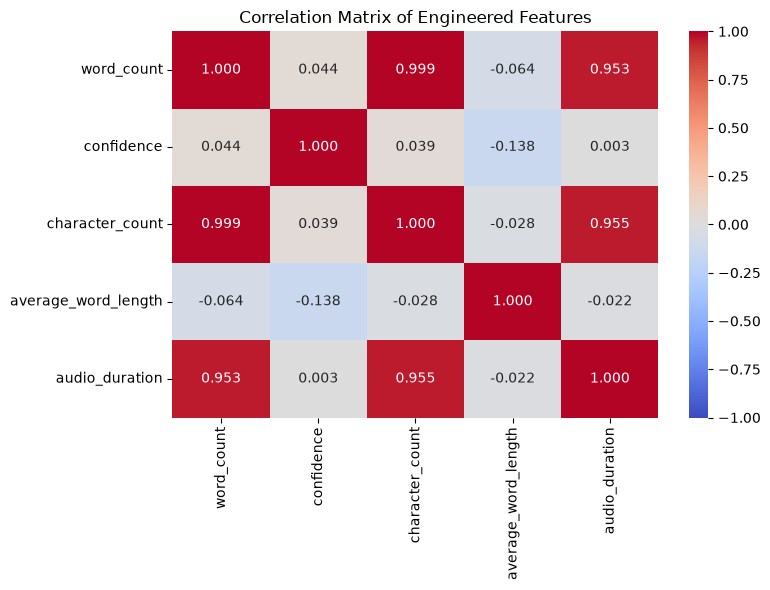

In [12]:

# Data Preparation: Feature Correlation Analysis
# Examine relationships among predictors and the target variable.

correlation_columns = feature_columns + [target_column]

feature_corr = df_model[correlation_columns].corr()

print("Feature correlation matrix:")
display(feature_corr.round(3))

# Visualize correlations among selected features and call duration
plt.figure(figsize=(8, 6))

sns.heatmap(
    feature_corr,
    annot=True,
    fmt=".3f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Correlation Matrix of Engineered Features")
plt.tight_layout()
plt.show()


In [13]:

# Data Preparation: Final Feature Selection
# Exclude character_count because it is highly correlated
# with word_count (r = 0.999).

selected_features = [
    "word_count",
    "confidence",
    "average_word_length"
]

# Define predictor variables (X) and target variable (y)
X = df_model[selected_features].copy()
y = df_model["audio_duration"].copy()

# Verify the selected data
print("Selected features:", selected_features)
print("X shape:", X.shape)
print("y shape:", y.shape)

display(X.head)


Selected features: ['word_count', 'confidence', 'average_word_length']
X shape: (3167, 3)
y shape: (3167,)


<bound method NDFrame.head of       word_count  confidence  average_word_length
0            237    0.908789             5.101266
1            363    0.881884             5.570248
2            327    0.903155             5.116208
3            450    0.849435             4.888889
4           1586    0.924117             4.954603
...          ...         ...                  ...
3162         282    0.882246             4.822695
3163        1172    0.872072             4.642491
3164         790    0.892218             4.864557
3165         394    0.870136             5.720812
3166         534    0.882037             4.338951

[3167 rows x 3 columns]>

In [14]:

# Data Preparation: Train/Test Split
# Split the dataset into 80% training and 20% testing.

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# Verify the split
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)


Training features: (2533, 3)
Testing features: (634, 3)
Training target: (2533,)
Testing target: (634,)


In [15]:

# Data Preparation: Check for transcript overlap
# Identify identical transcripts appearing in both datasets.

train_texts = set(
    df_model.loc[X_train.index, "text"]
)

test_texts = set(
    df_model.loc[X_test.index, "text"]
)

overlapping_texts = train_texts.intersection(test_texts)

print("Unique training transcripts:", len(train_texts))
print("Unique testing transcripts:", len(test_texts))
print("Overlapping transcripts:", len(overlapping_texts))

# Count test records affected by transcript overlap
affected_test_records = (
    df_model.loc[X_test.index, "text"]
    .isin(train_texts)
    .sum()
)

print("Affected test records:", affected_test_records)


Unique training transcripts: 2497
Unique testing transcripts: 632
Overlapping transcripts: 14
Affected test records: 14


In [16]:

# Data Preparation: Group-Aware Train/Test Split
# Keep identical transcripts in the same dataset to prevent leakage.

from sklearn.model_selection import GroupShuffleSplit

# Use transcript text as the grouping variable
groups = df_model["text"]

# Create an approximately 80/20 split
group_split = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    group_split.split(X, y, groups=groups)
)

# Replace the previous training and testing datasets
X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()

y_train = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()

# Verify that transcript groups do not overlap
train_texts = set(groups.iloc[train_idx])
test_texts = set(groups.iloc[test_idx])

overlap = train_texts.intersection(test_texts)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)
print("Overlapping transcripts:", len(overlap))


Training features: (2539, 3)
Testing features: (628, 3)
Training target: (2539,)
Testing target: (628,)
Overlapping transcripts: 0


**Feature Selection and Train-Test Splitting**

Following data cleaning, four numerical predictors were considered: transcript word count, transcription confidence, character count, and average word length.

Correlation analysis revealed a very strong relationship between word count and character count (r = 0.999), indicating substantial redundancy. Therefore, character count was excluded from the initial modeling feature set. The final predictors were word count, transcription confidence, and average word length, while audio duration in seconds was retained as the target variable.

To reduce potential data leakage, the dataset was divided using scikit-learn's `GroupShuffleSplit`, with transcript text serving as the grouping variable. This approach ensured that records containing identical transcripts were not distributed across both training and testing subsets.

The resulting split contained 2,539 training records (approximately 80.2%) and 628 testing records (approximately 19.8%). Verification confirmed zero identical transcripts shared between the two subsets.

This strategy supports a more reliable assessment of model generalization than a conventional random split for this dataset. However, it does not eliminate the possibility of semantically similar transcripts appearing in both subsets.

## Modeling<a class="anchor" id="modeling"></a>

### Model Selection and Configuration

Three supervised regression algorithms were selected to estimate completed call duration using transcript-derived numerical features.

**Linear Regression:** This model was selected as an interpretable baseline for examining linear relationships between the input features and call duration. It was trained using the default scikit-learn configuration.

**Random Forest Regression:** This ensemble learning method combines multiple decision trees and can capture nonlinear relationships between the features and target variable. The model was configured with 100 trees (`n_estimators=100`), a maximum tree depth of 10 (`max_depth=10`), and a minimum of two samples per leaf (`min_samples_leaf=2`). A fixed random state of 42 was used for reproducibility.

**Gradient Boosting Regression:** This ensemble method builds decision trees sequentially to reduce prediction errors. The model was configured with 100 boosting stages (`n_estimators=100`), a learning rate of 0.1 (`learning_rate=0.1`), and a maximum tree depth of 3 (`max_depth=3`). A fixed random state of 42 was used for reproducibility.

All three models were trained using the same group-aware training dataset and evaluated on the same held-out test dataset to ensure a consistent comparison (Pedregosa et al., 2011).

In [17]:

# Modeling: Linear Regression
# Train a baseline regression model using the selected features.

from sklearn.linear_model import LinearRegression

# Initialize the Linear Regression model
linear_model = LinearRegression()

# Train the model using the training dataset
linear_model.fit(X_train, y_train)

# Generate predictions for the test dataset
y_pred_linear = linear_model.predict(X_test)

# Display model coefficients
print("Linear Regression model trained successfully!")

print("\nIntercept:", round(linear_model.intercept_, 4))

print("\nFeature coefficients:")
for feature, coefficient in zip(
    X_train.columns,
    linear_model.coef_
):
    print(f"{feature}: {coefficient:.4f}")

print("\nFirst 5 predictions (seconds):")
print(y_pred_linear[:5])


Linear Regression model trained successfully!

Intercept: 633.0178

Feature coefficients:
word_count: 0.4524
confidence: -886.6886
average_word_length: 41.5826

First 5 predictions (seconds):
[146.55101591 286.71316215 737.16900121 314.77353683 227.75393236]


**Model Selection and Configuration**

**Selected Model**

Linear Regression was selected as the initial machine learning model to estimate completed call center conversation duration. The model was implemented using the `LinearRegression` class from the scikit-learn library.

**Why Linear Regression?**

Linear Regression is appropriate as an initial model because the target variable, `audio_duration`, is continuous and measured in seconds. Exploratory Data Analysis revealed a strong positive correlation between transcript word count and call duration (r = 0.953).

The model provides an interpretable baseline for examining how transcript-derived numerical features relate to call duration. Its performance can subsequently be compared with more complex regression algorithms to determine whether nonlinear models offer meaningful improvements.

**Model Features and Parameters**

The model uses three predictor variables:

- `word_count`: Number of transcribed words.
- `confidence`: Automatic speech recognition confidence score.
- `average_word_length`: Average length of words in the transcript.

The target variable is `audio_duration`, measured in seconds.

The model was trained using scikit-learn's `LinearRegression()` with its default configuration, including `fit_intercept=True` and `positive=False`. Model coefficients and the intercept were learned from the training data rather than manually specified.

The dataset was divided using a group-aware approximately 80/20 training/testing split, resulting in 2,539 training observations and 628 testing observations. Transcript text was used as the grouping variable to prevent identical transcripts from appearing in both subsets.

**Initial Model Results**

The fitted Linear Regression model produced an intercept of 633.0178 and the following coefficients:

- `word_count`: 0.4524
- `confidence`: -886.6886
- `average_word_length`: 41.5826

These coefficients describe the fitted linear relationship between the selected predictors and estimated call duration, holding the other predictors constant. They should not be interpreted as causal effects.

Predictive performance will be assessed separately using regression evaluation metrics, including Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and R².

In [18]:

# Modeling: Random Forest Regression
# Train a nonlinear regression model for comparison.

from sklearn.ensemble import RandomForestRegressor

# Initialize the Random Forest model
random_forest_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=10,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

# Train the model using the same training dataset
random_forest_model.fit(X_train, y_train)

# Generate predictions using the same test dataset
y_pred_rf = random_forest_model.predict(X_test)

print("Random Forest model trained successfully!")

print("\nModel parameters:")
print("Number of trees:", random_forest_model.n_estimators)
print("Maximum tree depth:", random_forest_model.max_depth)
print("Minimum samples per leaf:", random_forest_model.min_samples_leaf)

print("\nFeature importance:")
for feature, importance in zip(
    X_train.columns,
    random_forest_model.feature_importances_
):
    print(f"{feature}: {importance:.4f}")

print("\nFirst 5 predictions (seconds):")
print(y_pred_rf[:5])


Random Forest model trained successfully!

Model parameters:
Number of trees: 100
Maximum tree depth: 10
Minimum samples per leaf: 2

Feature importance:
word_count: 0.9577
confidence: 0.0233
average_word_length: 0.0190

First 5 predictions (seconds):
[144.00421445 241.41229733 660.22162229 316.60567835 193.26775002]


In [19]:

# Modeling: Gradient Boosting Regression
# Train a third regression model for comparison.

from sklearn.ensemble import GradientBoostingRegressor

# Initialize the Gradient Boosting model
gradient_boosting_model = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

# Train the model using the training dataset
gradient_boosting_model.fit(X_train, y_train)

# Generate predictions for the test dataset
y_pred_gb = gradient_boosting_model.predict(X_test)

print("Gradient Boosting model trained successfully!")

print("\nModel parameters:")
print("Number of estimators:", gradient_boosting_model.n_estimators)
print("Learning rate:", gradient_boosting_model.learning_rate)
print("Maximum tree depth:", gradient_boosting_model.max_depth)

print("\nFeature importance:")
for feature, importance in zip(
    X_train.columns,
    gradient_boosting_model.feature_importances_
):
    print(f"{feature}: {importance:.4f}")

print("\nFirst 5 predictions (seconds):")
print(y_pred_gb[:5])


Gradient Boosting model trained successfully!

Model parameters:
Number of estimators: 100
Learning rate: 0.1
Maximum tree depth: 3

Feature importance:
word_count: 0.9711
confidence: 0.0203
average_word_length: 0.0086

First 5 predictions (seconds):
[144.50341044 256.76662935 735.28811639 317.71283727 190.20777552]


## Evaluation<a class="anchor" id="evaluation"></a>

In [20]:

# Evaluation: Compare Regression Model Performance
# Evaluate all three models using the same test dataset.

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Store predictions from the trained models
model_predictions = {
    "Linear Regression": y_pred_linear,
    "Random Forest": y_pred_rf,
    "Gradient Boosting": y_pred_gb
}

# Calculate evaluation metrics
results = []

for model_name, predictions in model_predictions.items():
    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    results.append({
        "Model": model_name,
        "MAE (seconds)": mae,
        "RMSE (seconds)": rmse,
        "R² Score": r2
    })

# Create a comparison table
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="MAE (seconds)"
).reset_index(drop=True)

print("Regression Model Performance Comparison:")
display(results_df.round(4))


Regression Model Performance Comparison:


,Model,MAE (seconds),RMSE (seconds),R² Score
0,Linear Regression,79.2960,118.9681,0.9296
1,Gradient Boosting,80.0885,122.7612,0.9250
2,Random Forest,83.2379,148.8893,0.8897


**Regression Model Performance Analysis**

Three regression algorithms were evaluated using the same held-out test dataset of 628 call center conversations: Linear Regression, Random Forest Regression, and Gradient Boosting Regression.

Model performance was assessed using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and the coefficient of determination (R²).

**Linear Regression** achieved the best overall performance, with an MAE of 79.30 seconds, an RMSE of 118.97 seconds, and an R² of 0.9296. These results indicate that the model explains approximately 92.96% of the variation in completed-call duration within the test dataset.

**Gradient Boosting Regression** performed similarly, achieving an MAE of 80.09 seconds, an RMSE of 122.76 seconds, and an R² of 0.9250.

**Random Forest Regression** produced comparatively higher prediction errors, with an MAE of 83.24 seconds, an RMSE of 148.89 seconds, and an R² of 0.8897.

The results suggest that a relatively simple linear model is effective for estimating completed-call duration from transcript-derived features. More complex nonlinear algorithms did not improve performance under the configurations tested.

Based on the observed test results, Linear Regression is the preferred model because it combines the lowest prediction error with greater interpretability and computational simplicity.

However, these findings apply to the current dataset, feature selection, and model configurations. Further validation would be necessary before generalizing the results to other call center environments.

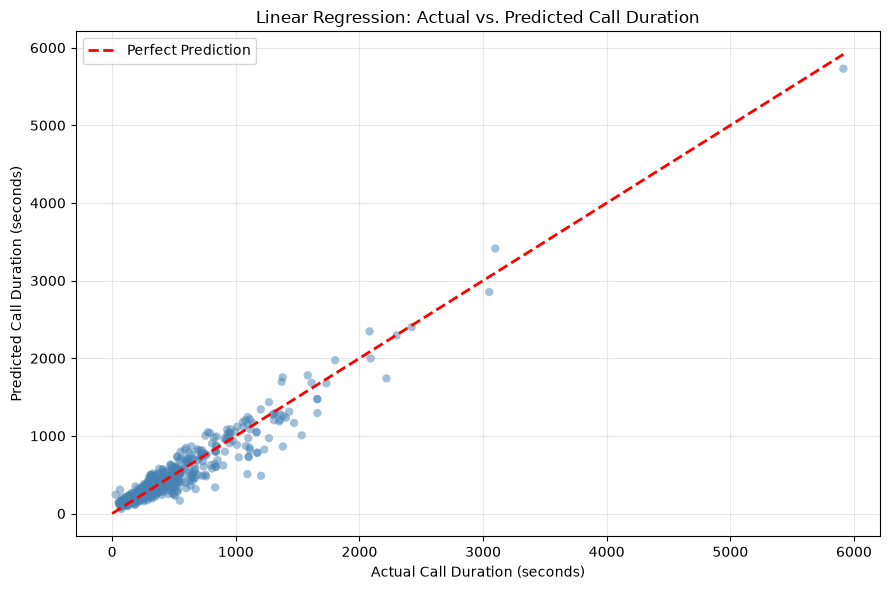

In [21]:

# Evaluation: Actual vs. Predicted Call Duration
# Visualize the predictions of the best-performing model.

plt.figure(figsize=(9, 6))

# Plot actual and predicted call durations
plt.scatter(
    y_test,
    y_pred_linear,
    alpha=0.5,
    color="steelblue",
    edgecolors="none"
)

# Draw the ideal prediction line
max_duration = max(
    y_test.max(),
    y_pred_linear.max()
)

plt.plot(
    [0, max_duration],
    [0, max_duration],
    color="red",
    linestyle="--",
    linewidth=2,
    label="Perfect Prediction"
)

plt.xlabel("Actual Call Duration (seconds)")
plt.ylabel("Predicted Call Duration (seconds)")
plt.title("Linear Regression: Actual vs. Predicted Call Duration")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


**Figure 6. Actual vs. Predicted Call Duration — Linear Regression**

The scatter plot compares actual call durations with the values predicted by the Linear Regression model for 628 test observations. The red dashed diagonal represents perfect predictions, where the predicted duration equals the actual duration.

Most observations are concentrated near the reference line, indicating that the model generally captures the relationship between transcript-derived features and completed-call duration.

However, some observations deviate from the reference line, particularly among longer calls, suggesting that prediction errors vary across the duration range.

These findings are consistent with the model's evaluation metrics: an R² score of 0.9296, a Mean Absolute Error (MAE) of 79.30 seconds, and a Root Mean Squared Error (RMSE) of 118.97 seconds.

Overall, the visualization supports the conclusion that Linear Regression provides a strong baseline for estimating completed-call duration, although individual predictions may still contain substantial errors, particularly for some longer conversations.

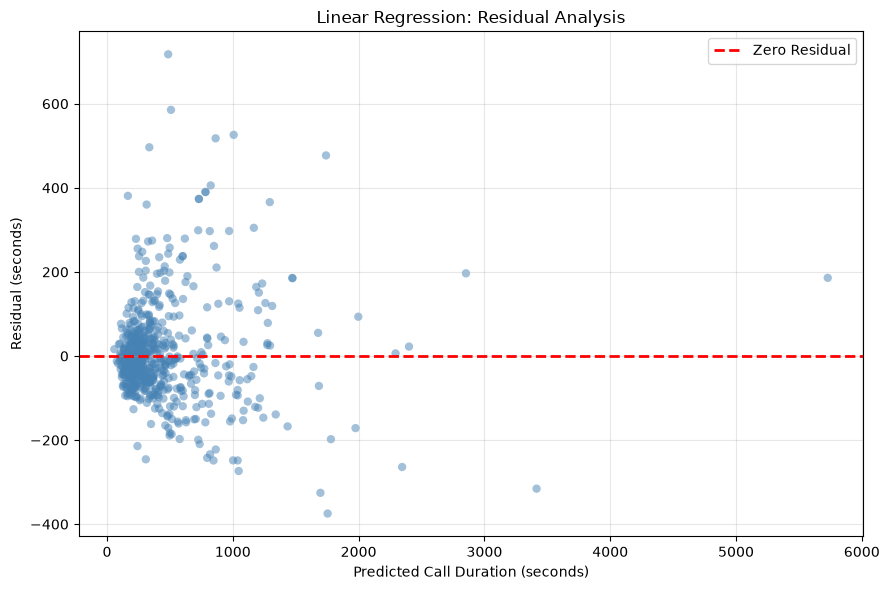

Mean residual: 4.49
Residual standard deviation: 118.88
Minimum residual: -374.75
Maximum residual: 717.63


In [22]:

# Evaluation: Residual Analysis for Linear Regression
# Residual = Actual Duration - Predicted Duration

residuals_linear = y_test.to_numpy() - y_pred_linear

# Create a residual scatter plot
plt.figure(figsize=(9, 6))

plt.scatter(
    y_pred_linear,
    residuals_linear,
    alpha=0.5,
    color="steelblue",
    edgecolors="none"
)

# Zero residual reference line
plt.axhline(
    y=0,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Zero Residual"
)

plt.xlabel("Predicted Call Duration (seconds)")
plt.ylabel("Residual (seconds)")
plt.title("Linear Regression: Residual Analysis")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Display residual statistics
print("Mean residual:",
      round(np.mean(residuals_linear), 2))

print("Residual standard deviation:",
      round(np.std(residuals_linear), 2))

print("Minimum residual:",
      round(np.min(residuals_linear), 2))

print("Maximum residual:",
      round(np.max(residuals_linear), 2))


**Figure 7. Residual Analysis of Linear Regression**

Residual analysis was conducted to examine the differences between actual and predicted call durations for the Linear Regression model. Residuals were calculated by subtracting predicted durations from actual durations.

The mean residual was 4.49 seconds, indicating a small average underestimation of call duration across the test observations. However, this near-zero average does not imply that individual prediction errors are small, because positive and negative residuals may offset each other.

The residual standard deviation was 118.88 seconds. Residual values ranged from −374.75 seconds to +717.63 seconds, indicating that some individual predictions deviated substantially from the observed call durations.

These findings suggest that, although Linear Regression achieved strong overall predictive performance (R² = 0.9296), notable errors remain for certain conversations.

The residual plot can also be used to assess whether errors exhibit systematic patterns or changing variability across predicted durations. Further investigation of these patterns would help identify potential limitations of the linear model.

**Evaluation Summary and Limitations**

This study evaluated three machine learning algorithms for estimating completed call center conversation duration: Linear Regression, Random Forest Regression, and Gradient Boosting Regression.

Among the three models, Linear Regression achieved the best performance on the held-out test dataset, with a Mean Absolute Error (MAE) of 79.30 seconds, a Root Mean Squared Error (RMSE) of 118.97 seconds, and an R² score of 0.9296.

The results indicate that transcript-derived numerical features can explain a substantial proportion of the variation in completed-call duration. Transcript word count was particularly informative, consistent with its strong positive correlation with call duration during exploratory analysis.

The comparison also demonstrated that more complex machine learning algorithms do not necessarily outperform simpler models. Under the configurations tested, neither Random Forest nor Gradient Boosting improved upon Linear Regression.

**Study Limitations**

Several limitations should be considered when interpreting these findings:

- **Post-call estimation:** The models rely on completed transcripts. Therefore, they cannot predict call duration before a conversation begins.
- **Dataset representativeness:** Results are based on a specific call center conversation dataset and may not generalize to other organizations, languages, or communication environments.
- **Prediction errors:** Although overall model performance was strong, residual analysis identified substantial errors for some individual calls.
- **Feature limitations:** The models use a small set of transcript-derived numerical features and do not directly capture conversation topics, customer sentiment, or interaction complexity.
- **Model validation:** A single group-aware train/test split was used. Additional cross-validation and hyperparameter tuning would provide stronger evidence of model stability.
- **Transcript similarity:** Group-aware splitting prevented identical transcripts from appearing in both subsets, but semantically similar conversations may still occur across training and testing data.

**Conclusion**

Linear Regression was selected as the preferred model because it achieved the lowest prediction errors while remaining computationally efficient and interpretable.

The findings demonstrate the potential of machine learning to estimate completed-call duration from transcript characteristics. Future research could investigate richer linguistic features, additional datasets, and more extensive model validation to improve prediction accuracy and generalizability.

## References<a class="anchor" id="references"></a>

So, A., So, W., Nagy, Z., Bagve, S., Doyle, J. W., Patil, A. P., Pathak, S. S., & Roy, S. (2020). *The applied artificial intelligence workshop*. Packt Publishing.

AIxBlock. (n.d.). *92k real-world call center scripts (English)* [Data set]. Hugging Face. https://huggingface.co/datasets/AIxBlock/92k-real-world-call-center-scripts-english

Waskom, M. L. (2021). seaborn: Statistical data visualization. Journal of Open Source Software, 6(60), 3021. https://doi.org/10.21105/joss.03021



**Disclaimer!** <font color='grey'>This notebook was prepared by <student name(s)> as a term project. The notebook is available for educational purposes only. There is no guarantee on the correctness of the content provided as it is a student work.
</font>